# Predicting Online Shoppers' Purchase Intention

**Assignment 1 — End-to-End Machine Learning Pipeline**
Track A (scikit-learn) | Binary classification | Random seed: 42

**Contents:** 1. Problem & data · 2. Setup · 3. Exploratory data analysis · 4. Cleaning & feature engineering · 5. Models, cross-validation & tuning · 6. Evaluation & model comparison · 7. Model selection & interpretation · 8. Limitations & future work · 9. Reproducibility & references

## 1. Problem and motivation
Predict whether an e-commerce browsing session ends in a purchase (`Revenue`) from session behaviour and context. A retailer could use a purchase-intent score to prioritise optional assistance (live chat, a reminder, a discount). False positives waste interventions; false negatives miss sales. Purchases are the minority class (only 15% of data show purchases), so accuracy alone is misleading; we use **average precision (AP)** as the primary metric (precision-recall measures are more informative than ROC on imbalanced data; Saito & Rehmsmeier, 2015) and report ROC-AUC, precision, recall, F1 and accuracy alongside it. This is predictive association, not causal inference.

*Why it is non-trivial:* strong class imbalance (≈15% purchases), heavily right-skewed counts and durations with extreme outliers, five integer-coded nominal variables plus three text categoricals that need encoding (some with very rare levels), exact duplicate rows, and a feature (`PageValues`) whose definition raises a target-leakage question.


## Dataset and source
**UCI Online Shoppers Purchasing Intention Dataset** — 12,330 sessions (one per user, collected over one year), 17 predictors and a binary target. Predictors cover page counts and time spent on administrative / informational / product pages, Google-Analytics bounce and exit rates, `PageValues`, proximity to a special day, integer-coded operating system / browser / region / traffic source, visitor type, month and weekend flag.

Sakar, C. O. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. DOI: [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q). Licence CC BY 4.0.



## 2. Setup
Imports, a fixed random seed, and an environment print-out (Python, OS, host and library versions) so the run can be traced to the machine / virtual lab it was executed on.

In [96]:
import json
import os
import platform
import socket
import warnings
from pathlib import Path

# numpy 2.x on macOS (Accelerate BLAS) emits spurious "divide by zero / overflow /
# invalid value encountered in matmul" RuntimeWarnings from scikit-learn's internal
# dot products. The results are finite and the metrics are identical across the numpy
# versions we tested, so we silence ONLY those three messages to keep outputs readable.
MATMUL_MESSAGES = ['divide by zero encountered in matmul',
                   'overflow encountered in matmul',
                   'invalid value encountered in matmul']
for msg in MATMUL_MESSAGES:
    warnings.filterwarnings('ignore', message=msg, category=RuntimeWarning)
# Parallel joblib workers start fresh interpreters, so pass the same filters via the environment.
os.environ['PYTHONWARNINGS'] = ','.join(f'ignore:{m}:RuntimeWarning' for m in MATMUL_MESSAGES)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

# dataset location
DATA_PATH = Path('data/online_shoppers_intention.csv')

# Create the figures and output folders into which model analysis will be written. 
FIG_DIR, OUT_DIR = Path('figures'), Path('output')
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {False: '#8c8c8c', True: '#2a6fdb', 0: '#8c8c8c', 1: '#2a6fdb'}


def save(fig, name):
    """Save a figure to figures/ (used by the PDF report) and display it inline."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


# Environment fingerprint -- the screenshot of this cell documents where the notebook ran.
print(f'Python {platform.python_version()} | {platform.platform()} | host: {socket.gethostname()}')
print(f'numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | '
      f'matplotlib {matplotlib.__version__} | seaborn {sns.__version__}')

Python 3.13.18 | macOS-27.2.1-arm64-arm-64bit-Mach-O | host: [redacted]
numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.6.1 | matplotlib 3.9.4 | seaborn 0.13.2


In [97]:
# Load the dataset and take a first look.
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Missing cells:', int(df.isna().sum().sum()),
      '| Exact duplicate rows:', int(df.duplicated().sum()))
# One row per column (transposed so it fits the page): dtype as loaded, distinct values, first rows.
# Note that OperatingSystems/Browser/Region/TrafficType load as integers although they are labels.
overview = df.head(3).T
overview.insert(0, 'dtype', df.dtypes.astype(str))
overview.insert(1, 'distinct values', df.nunique())
display(overview)

Shape: (12330, 18)
Missing cells: 0 | Exact duplicate rows: 125


,dtype,distinct values,0,1,2
Administrative,int64,27,0,0,0
Administrative_Duration,float64,3335,0.0,0.0,0.0
Informational,int64,17,0,0,0
Informational_Duration,float64,1258,0.0,0.0,0.0
ProductRelated,int64,311,1,2,1
ProductRelated_Duration,float64,9551,0.0,64.0,0.0
BounceRates,float64,1872,0.2,0.0,0.2
ExitRates,float64,4777,0.2,0.1,0.2
PageValues,float64,2704,0.0,0.0,0.0
SpecialDay,float64,6,0.0,0.0,0.0


## 3. Exploratory data analysis
### 3.1 Target balance

No purchase: 10,422 | Purchase: 1,908 | purchase rate: 15.47%


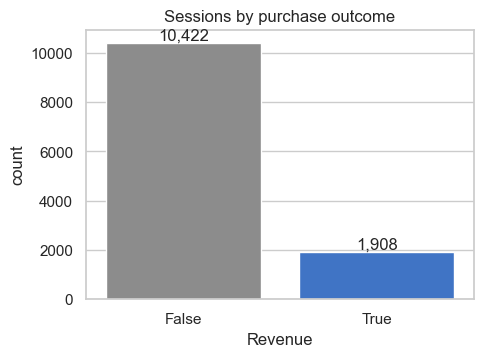

In [98]:
# Counts purchases and non-purchases and draws a bar chart
# We also make a not of the BASE_RATE - overall purchase percentage in the dataset. will be used as reference line in the plots.

counts = df['Revenue'].value_counts()
BASE_RATE = df['Revenue'].mean()          # overall purchase rate, used as a reference line below
print(f'No purchase: {counts[False]:,} | Purchase: {counts[True]:,} | purchase rate: {BASE_RATE:.2%}')

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x='Revenue', hue='Revenue', palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:                       # annotate bar heights
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Sessions by purchase outcome')
save(fig, 'eda_class_balance')

**Observation.** Only 1,908 of 12,330 sessions (15.5%, about 1 in 6.5) end in a purchase. A model that always predicts "no purchase" would be 84.5% accurate yet useless, so we 

1. stratify the split and CV folds (keep ratio of purchases and non-purchases the same in every split) 
2. use class-weighted models 
3. rank models by average precision, whose no-skill baseline (random guess) is the positive rate (0.155) rather than 0.5 (Saito & Rehmsmeier, 2015).

### 3.2 Numeric features by outcome

Start with an analysis of the boxplots of all the continuous measurements in the dataset.

Of the 17 input fields in each record, the following are continuous measurements:

| Field(s) | What it measures |
|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Number of pages of each type viewed |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | Seconds spent on each page type |
| `BounceRates`, `ExitRates` | Google Analytics rates for the pages visited |
| `PageValues` | Average "value" of the pages visited |

The remaining fields are not continuous measurements, so they are analysed with purchase-rate bar charts in Section 3.4 instead:

| Field(s) | Why no boxplot |
|---|---|
| `Month`, `VisitorType`, `Weekend` | Text or True/False labels |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Stored as numbers, but really nominal labels |
| `SpecialDay` | Only six distinct values, so a boxplot would not be useful |

Counts and durations have long right tails, so they are plotted on a `log1p` scale (the raw-scale boxplot is unreadable because a few sessions last over 17 hours). Bounce and exit rates are bounded in [0, 0.2] and are plotted raw.

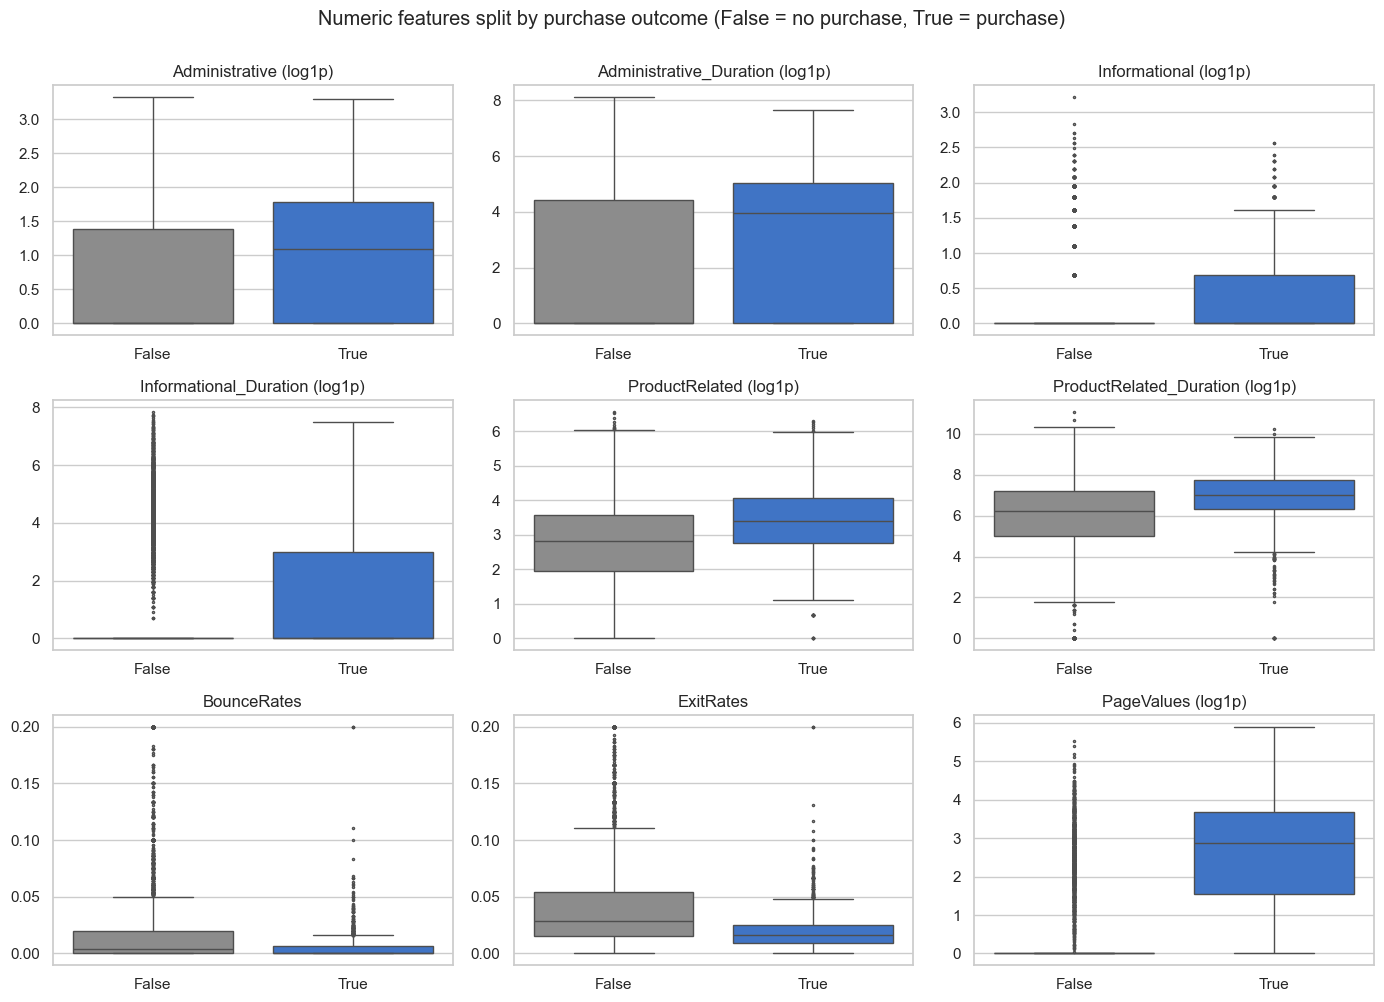

,median | no purchase,median | purchase,skewness,% zeros,% IQR outliers,max
Administrative,0.000,2.000,1.960,46.780,3.277,27.000
Administrative_Duration,0.000,52.367,5.616,47.875,9.505,3398.750
Informational,0.000,0.000,4.036,78.662,21.338,24.000
Informational_Duration,0.000,0.000,7.579,80.495,19.505,2549.375
ProductRelated,16.000,29.000,4.342,0.308,8.005,705.000
ProductRelated_Duration,510.190,1109.906,7.263,6.123,7.794,63973.522
BounceRates,0.004,0.000,2.948,44.753,12.579,0.200
ExitRates,0.029,0.016,2.149,0.616,8.913,0.200
PageValues,0.000,16.758,6.383,77.859,22.141,361.764


In [99]:
# Create 9 boxplots for numeric features split by purchase outcome.
# Log-transform features that are not rates to better visualize their distributions.
# Show figures in a 3x3 grid.

NUMERIC_RAW = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
               'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
RATE_COLS = ['BounceRates', 'ExitRates']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, NUMERIC_RAW):
    values = df[col] if col in RATE_COLS else np.log1p(df[col])
    sns.boxplot(x=df['Revenue'], y=values, hue=df['Revenue'], palette=PALETTE,
                legend=False, fliersize=1.5, ax=ax)
    ax.set_title(col if col in RATE_COLS else f'{col} (log1p)')
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('Numeric features split by purchase outcome (False = no purchase, True = purchase)', y=1.0)
fig.tight_layout()
save(fig, 'eda_numeric_by_outcome')

# Per-feature summary: medians by class, skewness, share of zeros and share of IQR outliers.
def iqr_outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean() * 100

numeric_summary = pd.DataFrame({
    'median | no purchase': df.loc[~df['Revenue'], NUMERIC_RAW].median(),
    'median | purchase': df.loc[df['Revenue'], NUMERIC_RAW].median(),
    'skewness': df[NUMERIC_RAW].skew(),
    '% zeros': (df[NUMERIC_RAW] == 0).mean() * 100,
    '% IQR outliers': df[NUMERIC_RAW].apply(iqr_outlier_share),
    'max': df[NUMERIC_RAW].max(),
}).round(3)
display(numeric_summary)

**Observations**
* **Buyers browse more.** Median product pages are 29 for buyers vs 16 for non-buyers, and median product-page time is 1,110 s vs 510 s. Median administrative time is 52 s for buyers but 0 s for non-buyers (account/checkout-type pages).
* **Buyers bounce and exit less.** Median exit rate is 0.016 vs 0.029. 700 sessions sit at the maximum bounce *and* exit rate of 0.2 (single-page visits), and only 0.4% of sessions with `BounceRates = 0.2` buy.
* **Zero-inflated and heavily skewed.** 79% of sessions view no informational page and 47% no administrative page; skewness ranges from 2.0 to 7.6. `ProductRelated_Duration` reaches 63,974 s (17.8 h) and 12 sessions exceed 5 hours.
* **Outlier decision.** The 1.5×IQR rule flags 3–21% of rows per feature — far too many to be entry errors; they are the natural long tail of session data (and for zero-inflated columns every non-zero value is "outlying"). We therefore keep them and use `log1p` rather than dropping or capping rows.
* `PageValues` separates the classes almost perfectly (median 0 vs 16.8) — investigated in Section 3.5.

### 3.3 Correlations
Spearman (rank) correlation is used because the features are skewed and zero-inflated; it captures monotonic relationships without being dominated by outliers.

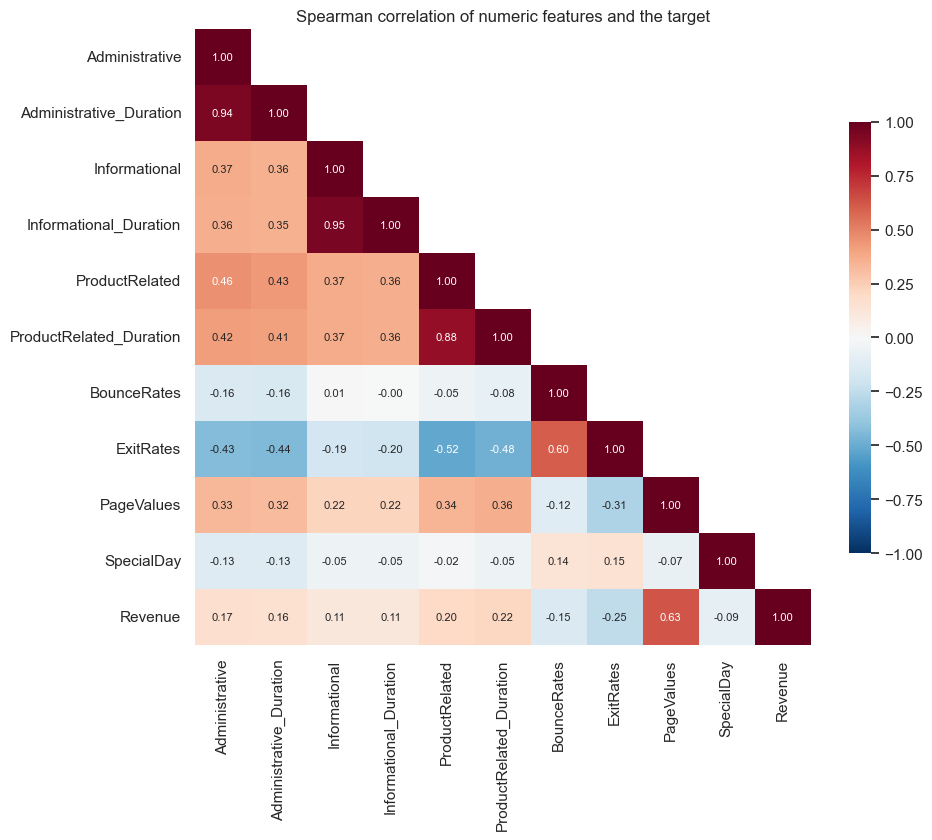

Strongest feature pairs:


rho
Informational_Duration  Informational            0.951
Administrative_Duration Administrative           0.941
ProductRelated_Duration ProductRelated           0.883
ExitRates               BounceRates              0.602
                        ProductRelated          -0.519
                        ProductRelated_Duration -0.477

Correlation with Revenue:


,Revenue
PageValues,0.626
ProductRelated_Duration,0.217
ProductRelated,0.199
Administrative,0.168
Administrative_Duration,0.164
Informational,0.114
Informational_Duration,0.112
SpecialDay,-0.087
BounceRates,-0.149
ExitRates,-0.254


In [100]:
# Create a Spearman correlation heat map for numeric features and the target variable
corr_cols = NUMERIC_RAW + ['SpecialDay']
corr = df[corr_cols].assign(Revenue=df['Revenue'].astype(int)).corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # show the lower triangle only
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'shrink': 0.7}, annot_kws={'size': 8}, ax=ax)
ax.grid(False)
ax.set_title('Spearman correlation of numeric features and the target')
save(fig, 'eda_correlation')

# Strongest feature-feature pairs and each feature's correlation with the target
pairs = (corr.drop(index='Revenue', columns='Revenue').where(np.tril(np.ones(corr.shape[0] - 1), k=-1) == 1)
         .stack().rename('rho').sort_values(key=abs, ascending=False))
print('Strongest feature pairs:')
display(pairs.head(6).round(3).to_frame())
print('Correlation with Revenue:')
display(corr['Revenue'].drop('Revenue').sort_values(ascending=False).round(3).to_frame())

**Observations.**
* **Count/duration pairs are nearly redundant:** ρ = 0.95 (informational), 0.94 (administrative), 0.88 (product). This is harmless for trees but means logistic-regression weights are unstable. So when using this data with logistic regression, we need to regularize by setting proper penalty (L1 vs L2) and penalty strength (`C`). It also suggests that we need to use ratio features like time *per* product page and the product *share* of session time — which carry information the raw pairs do not.
* **Correlation with the target:** `PageValues` 0.63 stands far above every other feature (next: `ExitRates` −0.25, `ProductRelated_Duration` 0.22). This can be considered as a red flag as we do not expect any single feature to so strongly predictive on its own. This suggests that we remove `PageValues` field from the model inputs to eliminate this skew. Removing this field will reduce model performance, but will be more generalized.
* `SpecialDay` is weakly negative (−0.09) — examined below.

### 3.4 Purchase rate by categorical context
Each bar is the percentage of sessions **in that group** that ended in a purchase (e.g. weekday purchases ÷ weekday sessions), so the bars in a panel do not add up to 100%. The dashed line is the overall purchase rate (15.5%), so bars above it convert better than average. Traffic types with fewer than 100 sessions are omitted from the plot because their rates are too noisy to read; the encoder later pools only the very rare ones (< 20 training rows) into an "infrequent" column.

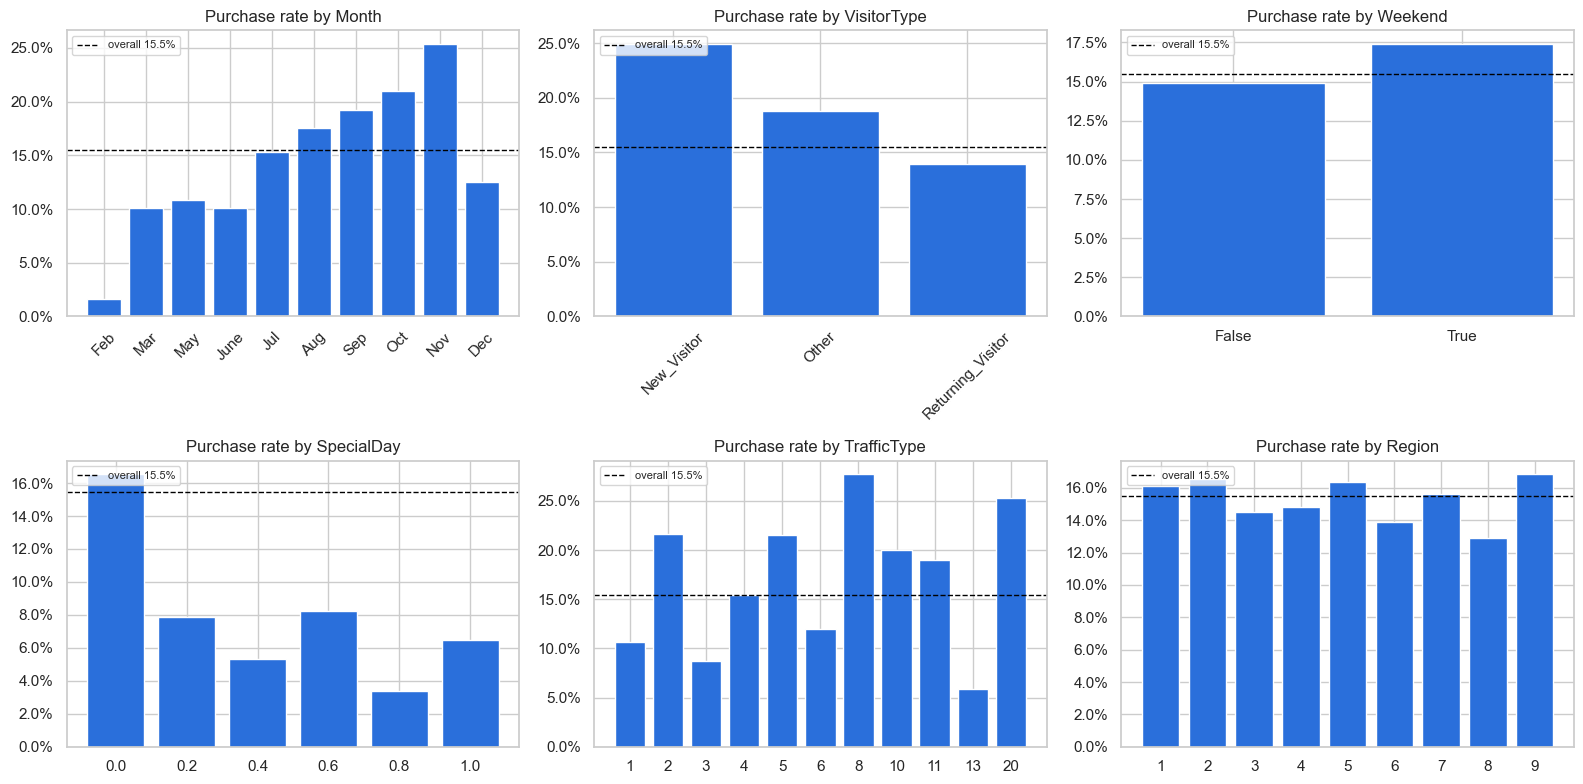

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
purchase %,1.6,10.1,10.9,10.1,15.3,17.6,19.2,20.9,25.4,12.5
n,184.0,1907.0,3364.0,288.0,432.0,433.0,448.0,549.0,2998.0,1727.0


VisitorType,New_Visitor,Other,Returning_Visitor
purchase %,24.9,18.8,13.9
n,1694.0,85.0,10551.0


Weekend,False,True
purchase %,14.9,17.4
n,9462.0,2868.0


SpecialDay,0.0,0.2,0.4,0.6,0.8,1.0
purchase %,16.5,7.9,5.3,8.3,3.4,6.5
n,11079.0,178.0,243.0,351.0,325.0,154.0


In [101]:
MONTH_ORDER = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']  # no Jan/Apr in the data
panels = ['Month', 'VisitorType', 'Weekend', 'SpecialDay', 'TrafficType', 'Region']
rate_tables = {}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, panels):
    rates = df.groupby(col)['Revenue'].agg(rate='mean', n='size')
    if col == 'Month':
        rates = rates.reindex(MONTH_ORDER)
    if col == 'TrafficType':
        rates = rates[rates['n'] >= 100]
    rate_tables[col] = rates
    ax.bar(rates.index.astype(str), rates['rate'], color='#2a6fdb')
    ax.axhline(BASE_RATE, ls='--', color='black', lw=1, label=f'overall {BASE_RATE:.1%}')
    ax.set_title(f'Purchase rate by {col}')
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.tick_params(axis='x', rotation=45 if col in ('Month', 'VisitorType') else 0)
    ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()
save(fig, 'eda_purchase_rate_by_category')

for col in ['Month', 'VisitorType', 'Weekend', 'SpecialDay']:
    display(rate_tables[col].assign(rate=lambda t: (t['rate'] * 100).round(1)).rename(columns={'rate': 'purchase %'}).T)

**Observations.**
* **Strong seasonality.** The purchase rate climbs from 1.6% in February to 25.4% in November, then drops to 12.5% in December. May and November together hold 51.6% of all sessions yet convert very differently (10.9% vs 25.4%). January and April are absent, so the model cannot say anything about them.
* **New visitors convert more** than returning ones (24.9% vs 13.9%), plausibly because returning visitors include many browse/compare sessions.
* **Weekend** sessions convert slightly more (17.4% vs 14.9%) — a weak signal.
* **Special days convert *less*** (3.4–8.3% vs 16.5% on ordinary days). Every special-day session falls in February or May, two low months, but the effect survives within May (6.4% vs 13.2%), so it is not only a month effect — perhaps shoppers research gifts before buying close to the date.
* **Traffic source matters:** traffic type 8 converts at 27.7% (n = 343) vs 5.8% for type 13 (n = 738). **Region** barely matters (12.9–16.8%). These integer codes have no order (type 13 is not "more" than type 8), which is why they are one-hot encoded instead of scaled as numbers.

### 3.5 Leakage check: `PageValues`
UCI defines `PageValues` as *"the average value for a web page that a user visited before completing an e-commerce transaction"* — it is computed from transaction pages, so it partly encodes the outcome. We quantify how much signal it carries on its own.

In [102]:
pv_pos = df['PageValues'] > 0
pv_auc = roc_auc_score(df['Revenue'], df['PageValues'])
print(f"Sessions with PageValues > 0: {pv_pos.mean():.1%}")
print(f"Purchase rate when PageValues > 0: {df.loc[pv_pos, 'Revenue'].mean():.1%} "
      f"vs {df.loc[~pv_pos, 'Revenue'].mean():.1%} when PageValues = 0")
print(f"ROC-AUC of PageValues used ALONE as a score: {pv_auc:.3f}")

Sessions with PageValues > 0: 22.1%
Purchase rate when PageValues > 0: 56.3% vs 3.9% when PageValues = 0
ROC-AUC of PageValues used ALONE as a score: 0.863


**Observation and decision.** Sessions with a non-zero `PageValues` buy 56.3% of the time vs 3.9% otherwise, and the raw column alone reaches ROC-AUC 0.863 — higher than any model built without it (Section 6). Because the value is attributed from pages that precede a completed transaction, purchasing sessions mechanically tend to receive a non-zero value, and it would not be available in that form mid-session, when an intervention would happen. We therefore **exclude `PageValues`** from the features. Section 7 quantifies what this costs in reported performance.

## 4. Cleaning, preprocessing and feature engineering
| Issue found in EDA | Decision |
|---|---|
| No missing cells | Verified above. `ProductTimePerPage` (engineered) is undefined when no product page was viewed, so median imputation inside the pipeline is genuinely used; imputers also guard against missing values in new data. |
| 125 exact duplicate rows | Retained: there is no session ID, and identical feature vectors are plausible for short sessions (e.g. one product page, zero duration). |
| Heavy right skew / outliers in counts and durations | Kept (they are plausible long sessions, not errors) but `log1p`-transformed, which compresses the tails for the linear model; tree models are insensitive to monotonic transforms. |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` are integer *codes* | Converted to categories and one-hot encoded — "Region 9" is not nine times "Region 1". Levels with < 20 training rows are pooled into an "infrequent" column so rare codes do not create noisy columns. |
| `Month`, `VisitorType`, `Weekend` | One-hot encoded. |
| `PageValues` leaks the outcome | Excluded from the predictive feature set (a sensitivity check in Section 7 shows its effect). |
| Class imbalance (≈15% positive) | Stratified split and folds; class-weighted losses; AP as the tuning metric. |

**Engineered features:** `TotalPages`, `TotalDuration`, `ProductTimePerPage` (average seconds per product page) and `ProductDurationShare` (share of session time spent on product pages). All scaling, encoding and imputation is inside a `Pipeline`, so in every cross-validation round it is fitted only on the four training folds and then applied to the validation fold. This ensures that no information from the validation fold, or from the test set, leaks into how the training data is prepared.

In [103]:
data = df.copy()

# Integer-coded identifiers are nominal labels, not quantities -> treat as categorical strings.
CODE_COLS = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
data[CODE_COLS] = data[CODE_COLS].astype(str)
data['Weekend'] = data['Weekend'].astype(str)
data['Revenue'] = data['Revenue'].astype(int)          # target: 1 = purchase

# --- Feature engineering -------------------------------------------------------------
page_cols = ['Administrative', 'Informational', 'ProductRelated']
dur_cols = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
data['TotalPages'] = data[page_cols].sum(axis=1)
data['TotalDuration'] = data[dur_cols].sum(axis=1)
# NaN when no product page / no time recorded; imputed with the training median in the pipeline.
data['ProductTimePerPage'] = data['ProductRelated_Duration'] / data['ProductRelated'].replace(0, np.nan)
data['ProductDurationShare'] = data['ProductRelated_Duration'] / data['TotalDuration'].replace(0, np.nan)
print('Rows with undefined ProductTimePerPage:', int(data['ProductTimePerPage'].isna().sum()),
      '| ProductDurationShare:', int(data['ProductDurationShare'].isna().sum()))

# log1p for skewed non-negative counts/durations (bounded rates and shares are left as they are).
SKEWED = page_cols + dur_cols + ['TotalPages', 'TotalDuration', 'ProductTimePerPage']
data[SKEWED] = np.log1p(data[SKEWED])

# Explicit feature lists (PageValues deliberately excluded -- see section 3.5).
NUM_COLS = SKEWED + ['BounceRates', 'ExitRates', 'SpecialDay', 'ProductDurationShare']
CAT_COLS = ['Month', 'VisitorType', 'Weekend'] + CODE_COLS
X, y = data[NUM_COLS + CAT_COLS], data['Revenue']

# Stratified 80/20 hold-out: the test set is not touched until final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape,
      '| positive rate train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))


def make_preprocessor(num_cols, cat_cols):
    """Median-impute + standardise numerics; mode-impute + one-hot encode categoricals."""
    num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale', StandardScaler())])
    cat_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                  min_frequency=20, sparse_output=False))])
    return ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])


preprocess = make_preprocessor(NUM_COLS, CAT_COLS)
n_features_out = preprocess.fit(X_train).transform(X_train.head()).shape[1]
print(f'{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical inputs -> {n_features_out} model features')

Rows with undefined ProductTimePerPage: 38 | ProductDurationShare: 720
Train: (9864, 20) | Test: (2466, 20) | positive rate train/test: 0.155 0.155
13 numeric + 7 categorical inputs -> 69 model features


## 5. Models, cross-validation and hyperparameter tuning
Five algorithm families of different kinds are compared: a linear model, a single tree, two bagging ensembles and a boosting ensemble. Each is tuned with `GridSearchCV` over the grid below using **5-fold shuffled stratified cross-validation on the training set**, maximising average precision. Every model uses class weighting for the imbalance.

| Model | Why include it | Grid |
|---|---|---|
| Logistic Regression | Interpretable linear baseline | `C` ∈ {0.01, 0.1, 1, 10}, penalty ∈ {L1, L2} |
| Decision Tree | Non-linear, interpretable rules | depth ∈ {4, 6, 8, 12}, min leaf ∈ {5, 20, 50}, criterion ∈ {gini, entropy} |
| Random Forest | Bagged trees, low variance | depth ∈ {None, 16}, min leaf ∈ {2, 8}, max features ∈ {√p, 0.5} |
| Extra Trees | More randomised bagging | same as Random Forest |
| Histogram Gradient Boosting | Boosted trees, usually strongest on tabular data | learning rate ∈ {0.05, 0.1}, max leaf nodes ∈ {15, 31}, min leaf ∈ {20, 50}, L2 ∈ {0, 1}; early stopping |

In [104]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
forest_grid = {'model__max_depth': [None, 16], 'model__min_samples_leaf': [2, 8],
               'model__max_features': ['sqrt', 0.5]}

MODELS = {
    'Logistic Regression': (
        LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=2000,
                           random_state=RANDOM_STATE),
        {'model__C': [0.01, 0.1, 1, 10], 'model__penalty': ['l1', 'l2']}),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'model__max_depth': [4, 6, 8, 12], 'model__min_samples_leaf': [5, 20, 50],
         'model__criterion': ['gini', 'entropy']}),
    'Random Forest': (
        RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                               n_jobs=-1, random_state=RANDOM_STATE),
        forest_grid),
    'Extra Trees': (
        ExtraTreesClassifier(n_estimators=300, class_weight='balanced',
                             n_jobs=-1, random_state=RANDOM_STATE),
        forest_grid),
    'Gradient Boosting': (
        HistGradientBoostingClassifier(class_weight='balanced', max_iter=300, early_stopping=True,
                                       validation_fraction=0.1, n_iter_no_change=20,
                                       random_state=RANDOM_STATE),
        {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31],
         'model__min_samples_leaf': [20, 50], 'model__l2_regularization': [0.0, 1.0]}),
}

searches = {}
for name, (estimator, grid) in MODELS.items():
    pipe = Pipeline([('prep', preprocess), ('model', estimator)])
    search = GridSearchCV(pipe, grid, scoring='average_precision', cv=cv,
                          n_jobs=-1, refit=True, error_score='raise')
    search.fit(X_train, y_train)            # tuning uses the training set only
    searches[name] = search
    best_std = search.cv_results_['std_test_score'][search.best_index_]
    params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    print(f'{name:20s} Cross-Validated Average Precision {search.best_score_:.4f} ± {best_std:.4f} '
          f'({len(search.cv_results_["params"])} configs) best: {params}')

Logistic Regression  Cross-Validated Average Precision 0.3381 ± 0.0135 (8 configs) best: {'C': 0.1, 'penalty': 'l1'}
Decision Tree        Cross-Validated Average Precision 0.3267 ± 0.0137 (24 configs) best: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 5}
Random Forest        Cross-Validated Average Precision 0.3834 ± 0.0218 (8 configs) best: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 8}
Extra Trees          Cross-Validated Average Precision 0.3849 ± 0.0277 (8 configs) best: {'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 8}
Gradient Boosting    Cross-Validated Average Precision 0.3704 ± 0.0196 (16 configs) best: {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}


## 6. Evaluation and model comparison
Each tuned model is refitted on the full training set and evaluated once on the untouched 20% hold-out. Threshold-free metrics (AP, ROC-AUC) compare ranking quality; precision, recall, F1 and accuracy use the default 0.5 threshold on class-weighted probabilities.

In [105]:
rows = []
for name, search in searches.items():
    model = search.best_estimator_
    score = model.predict_proba(X_test)[:, 1]   # purchase probability
    pred = model.predict(X_test)                # default 0.5 threshold
    rows.append({
        'Model': name,
        'CV AP': search.best_score_,
        'CV AP std': search.cv_results_['std_test_score'][search.best_index_],
        'Test AP': average_precision_score(y_test, score),
        'Test ROC-AUC': roc_auc_score(y_test, score),
        'Test Precision': precision_score(y_test, pred, zero_division=0),
        'Test Recall': recall_score(y_test, pred, zero_division=0),
        'Test F1': f1_score(y_test, pred, zero_division=0),
        'Test Accuracy': accuracy_score(y_test, pred),
        'Best params': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
    })
# Sorted by the selection criterion (CV AP), not by test results.
results = pd.DataFrame(rows).sort_values('CV AP', ascending=False).reset_index(drop=True)
results.to_csv(OUT_DIR / 'model_comparison.csv', index=False)
display(results.drop(columns='Best params').round(4))

,Model,CV AP,CV AP std,Test AP,Test ROC-AUC,Test Precision,Test Recall,Test F1,Test Accuracy
0,Extra Trees,0.3849,0.0277,0.3694,0.7695,0.3206,0.5942,0.4165,0.7421
1,Random Forest,0.3834,0.0218,0.3586,0.7683,0.3321,0.4686,0.3887,0.7717
2,Gradient Boosting,0.3704,0.0196,0.3719,0.7722,0.2867,0.7513,0.4150,0.6719
3,Logistic Regression,0.3381,0.0135,0.3256,0.7437,0.2564,0.7304,0.3796,0.6302
4,Decision Tree,0.3267,0.0137,0.3046,0.7088,0.2586,0.6309,0.3668,0.6626


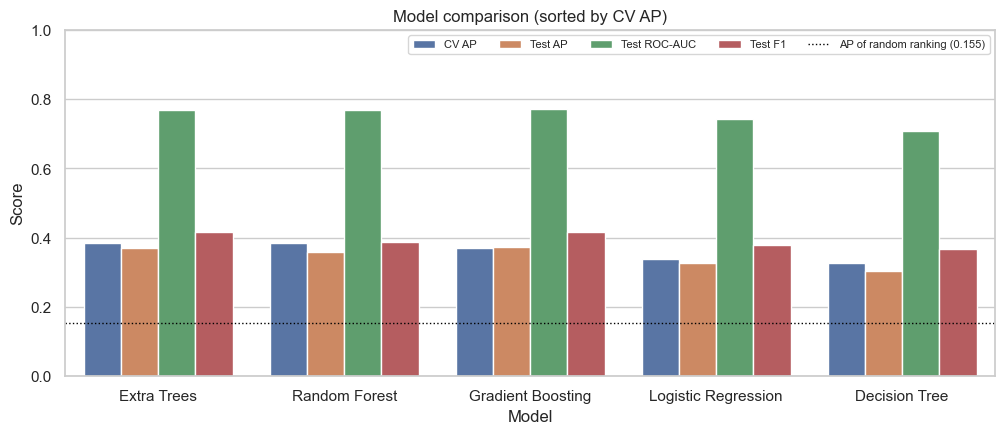

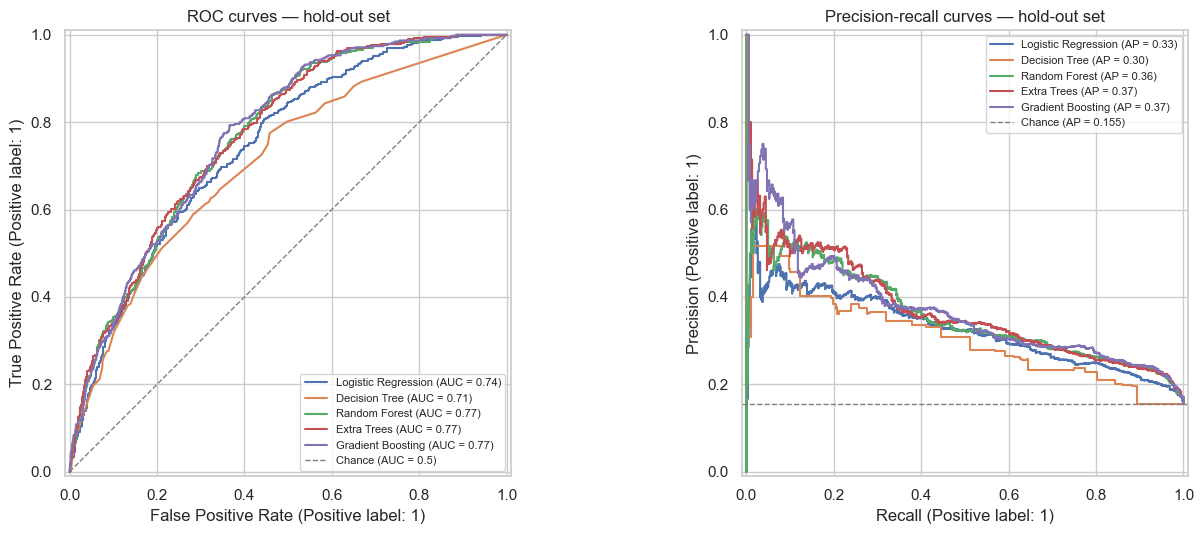

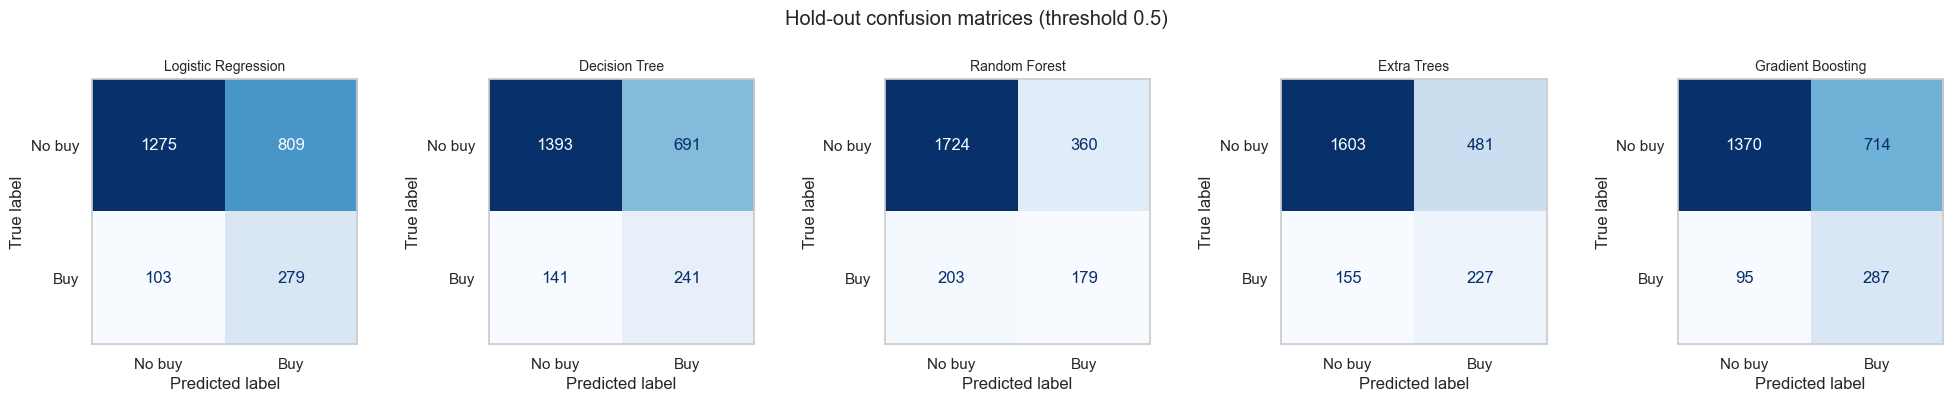

In [106]:
# --- Comparison bar chart ---------------------------------------------------------------
plot_df = results.melt(id_vars='Model', value_vars=['CV AP', 'Test AP', 'Test ROC-AUC', 'Test F1'],
                       var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', ax=ax)
ax.axhline(BASE_RATE, ls=':', color='black', lw=1, label=f'AP of random ranking ({BASE_RATE:.3f})')
ax.set_ylim(0, 1)
ax.set_title('Model comparison (sorted by CV AP)')
ax.legend(ncol=5, fontsize=8, loc='upper right')
save(fig, 'model_comparison')

# --- ROC and precision-recall curves for every model on the hold-out set -------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.5))
for name, search in searches.items():
    RocCurveDisplay.from_estimator(search.best_estimator_, X_test, y_test, ax=ax_roc, name=name)
    PrecisionRecallDisplay.from_estimator(search.best_estimator_, X_test, y_test, ax=ax_pr, name=name)
ax_roc.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Chance (AUC = 0.5)')
ax_pr.axhline(y_test.mean(), ls='--', color='grey', lw=1, label=f'Chance (AP = {y_test.mean():.3f})')
ax_roc.set_title('ROC curves — hold-out set')
ax_pr.set_title('Precision-recall curves — hold-out set')
ax_roc.legend(fontsize=8, loc='lower right')
ax_pr.legend(fontsize=8, loc='upper right')
fig.tight_layout()
save(fig, 'roc_pr_all_models')

# --- Confusion matrices at the default threshold ---------------------------------------------
fig, axes = plt.subplots(1, len(searches), figsize=(4 * len(searches), 3.8))
for ax, (name, search) in zip(axes, searches.items()):
    ConfusionMatrixDisplay.from_estimator(search.best_estimator_, X_test, y_test, ax=ax,
                                          display_labels=['No buy', 'Buy'], colorbar=False,
                                          cmap='Blues')
    ax.set_title(name, fontsize=10)
    ax.grid(False)
fig.suptitle('Hold-out confusion matrices (threshold 0.5)', y=1.02)
fig.tight_layout()
save(fig, 'confusion_matrices')

**Observations.**
* **All five models clearly beat chance** (hold-out AP 0.30–0.37 vs 0.155; ROC-AUC 0.71–0.77).
* **The three ensembles are effectively tied.** Their CV AP lies within 0.015 (0.370–0.385) while each has a fold-to-fold standard deviation of 0.02–0.03. Logistic regression (0.338) and the single tree (0.327) are clearly behind, showing that non-linear interactions (e.g. month × engagement) matter.
* **Hold-out rankings shuffle slightly within the tied group:** Gradient Boosting has the highest test AP (0.372) and ROC-AUC (0.772), Extra Trees the highest F1 (0.417). This is consistent with sampling noise on 382 test purchases.
* **The confusion matrices show different operating points, not different ranking ability.** At the 0.5 threshold Random Forest is conservative (finds 179 of 382 buyers with 360 false alarms; precision 0.33, recall 0.47), whereas Gradient Boosting and Logistic Regression are aggressive (recall 0.75 / 0.73 at precision 0.29 / 0.26, with 714 / 809 false alarms). The PR curves overlap, so the threshold — not the model — should be set from intervention costs.
* **Accuracy is misleading here:** it is highest (0.77) for the model that predicts "buy" least often, which is why it is not used for selection.

## 7. Final model selection and interpretation
The rule fixed *before* looking at the test set: choose the model with the highest mean cross-validated AP on the training data.

In [107]:
best_name = results.loc[0, 'Model']
runner_up = results.loc[1]
best_search = searches[best_name]
best = best_search.best_estimator_
gap = results.loc[0, 'CV AP'] - runner_up['CV AP']
print(f'Selected by CV AP: {best_name} ({results.loc[0, "CV AP"]:.4f} ± {results.loc[0, "CV AP std"]:.4f}); '
      f'runner-up {runner_up["Model"]} by {gap:.4f}')
print('Best hyperparameters:', results.loc[0, 'Best params'])
print()
print(classification_report(y_test, best.predict(X_test),
                            target_names=['No purchase', 'Purchase'], digits=3, zero_division=0))

Selected by CV AP: Extra Trees (0.3849 ± 0.0277); runner-up Random Forest by 0.0015
Best hyperparameters: {'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 8}

              precision    recall  f1-score   support

 No purchase      0.912     0.769     0.834      2084
    Purchase      0.321     0.594     0.417       382

    accuracy                          0.742      2466
   macro avg      0.616     0.682     0.625      2466
weighted avg      0.820     0.742     0.770      2466



**Which inputs drive the selected model?** Permutation importance on the hold-out set measures the drop in AP when a single original input column is shuffled (10 repeats). It works on the raw columns, so a one-hot-encoded variable such as `Month` is scored as a whole.

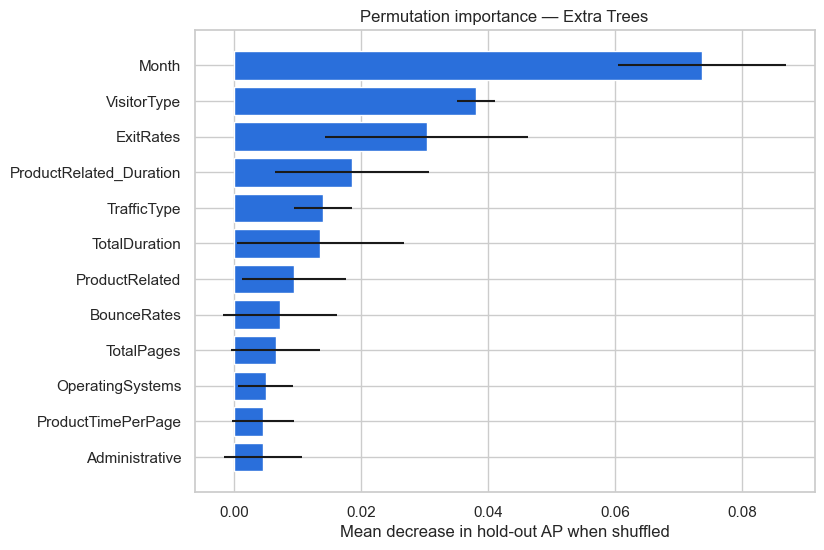

,feature,mean AP drop,std
0,Month,0.0737,0.0133
1,VisitorType,0.0381,0.0030
2,ExitRates,0.0303,0.0161
3,ProductRelated_Duration,0.0185,0.0122
4,TrafficType,0.0140,0.0046
5,TotalDuration,0.0135,0.0132
6,ProductRelated,0.0094,0.0082
7,BounceRates,0.0072,0.0090
8,TotalPages,0.0065,0.0071
9,OperatingSystems,0.0049,0.0043


In [108]:
perm = permutation_importance(best, X_test, y_test, scoring='average_precision',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({'feature': X_test.columns, 'mean AP drop': perm.importances_mean,
                            'std': perm.importances_std})
              .sort_values('mean AP drop', ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 6))
top = importance.head(12).iloc[::-1]
ax.barh(top['feature'], top['mean AP drop'], xerr=top['std'], color='#2a6fdb')
ax.set_xlabel('Mean decrease in hold-out AP when shuffled')
ax.set_title(f'Permutation importance — {best_name}')
save(fig, 'permutation_importance')
display(importance.head(12).round(4))

**Sensitivity check — what if `PageValues` were included?** Same selected model and hyperparameters, 5-fold CV on the training set only (the test set is not used).

In [109]:
X_pv = X.assign(PageValues=np.log1p(df['PageValues']))
pv_pipe = Pipeline([('prep', make_preprocessor(NUM_COLS + ['PageValues'], CAT_COLS)),
                    ('model', clone(best.named_steps['model']))])
pv_scores = cross_val_score(pv_pipe, X_pv.loc[X_train.index], y_train, cv=cv,
                            scoring='average_precision', n_jobs=-1)
print(f'{best_name} CV AP without PageValues: {best_search.best_score_:.4f}')
print(f'{best_name} CV AP with    PageValues: {pv_scores.mean():.4f} ± {pv_scores.std():.4f}')

# Key numbers consumed by make_pdfs.py so the report never drifts from the notebook.
summary = {'base_rate': float(BASE_RATE), 'pagevalues_alone_auc': float(pv_auc),
           'best_model': best_name, 'best_params': results.loc[0, 'Best params'],
           'cv_ap_without_pagevalues': float(best_search.best_score_),
           'cv_ap_with_pagevalues': float(pv_scores.mean()),
           'top_features': importance.head(5)[['feature', 'mean AP drop']].round(4).to_dict('records')}
_ = (OUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, default=str))

Extra Trees CV AP without PageValues: 0.3849
Extra Trees CV AP with    PageValues: 0.7539 ± 0.0159


### Final model: Extra Trees
(`max_depth = 16`, `max_features = 0.5`, `min_samples_leaf = 8`, 300 trees, balanced class weights)

* **Why:** it has the highest mean CV AP (0.385 ± 0.028) — the criterion fixed before the test set was used. Its hold-out AP (0.369) is close to its CV AP, so tuning did not overfit. At the default threshold it gives the best F1 (0.417) with a usable balance of precision and recall (0.32 / 0.59). It is also fast to train in parallel, needs no feature scaling, and is less sensitive to the skewed inputs than the linear model.
* **Honest caveat:** Random Forest (0.383) and Gradient Boosting (0.370) are within one CV standard deviation, and Gradient Boosting scores marginally higher on the hold-out AP (0.372 vs 0.369). Switching to it because of that would be selecting on the test set. Any of the three ensembles is a defensible choice; separating them would need repeated or nested CV.
* **What drives predictions:** `Month` is by far the most important input (shuffling it lowers AP by 0.074), followed by `VisitorType` (0.038), `ExitRates` (0.030), product-page time (0.018) and `TrafficType` (0.014). This matches the EDA: seasonality, visitor type and engagement. `Region`, `Weekend` and `Browser` do not appear in the top 12.
* **`PageValues` sensitivity:** including it would almost double CV AP (0.385 → 0.754). Much of the high performance often reported for this dataset therefore comes from this single leakage-prone field. Our lower numbers are a more realistic estimate of what can be predicted *before* a transaction happens.

## 8. Discussion, limitations and future work
**Summary.** Without `PageValues`, session behaviour and context give a useful but modest purchase-intent signal: the selected Extra Trees model ranks sessions about 2.4× better than random (hold-out AP 0.37 vs 0.155) with ROC-AUC 0.77. Seasonality, visitor type and engagement are the main drivers, and the three tree ensembles perform equivalently.

**Limitations**
* **Single retailer, one year, collected several years ago** — behaviour and traffic sources may not transfer to other shops or to today.
* **Random split.** Sessions from the same month appear in both train and test, and `Month` is the strongest feature, so a time-based split would probably give lower scores. January and April are missing entirely.
* **Threshold and calibration.** The 0.5 threshold on class-weighted models is not tied to business costs, and class weighting distorts probabilities, so the scores are not calibrated likelihoods.
* **Duplicates.** The 125 duplicate rows (all non-purchase single-page bounces) were kept; they add a few very easy negatives.
* **Anonymised codes.** Traffic type, region, browser and OS are anonymous integers, so findings such as "traffic type 8 converts well" cannot be acted on directly.
* **Interpretation.** Permutation importance splits credit between correlated features (page counts vs durations) and may understate each. All findings are associations, not causes.
* **Search budget.** The grids are compact; the ensembles could not be separated statistically.

**Future work**
1. Time-based validation (train on earlier months, test on later ones).
2. Choose the decision threshold from a cost matrix using out-of-fold CV predictions, and calibrate probabilities (`CalibratedClassifierCV`).
3. Repeated or nested CV to compare the top ensembles; wider randomised/Bayesian search; try XGBoost, LightGBM or CatBoost (native categorical handling).
4. Build a leakage-free version of `PageValues` from pages viewed *so far* in the session, and, with raw clickstreams, sequence models as in Sakar et al. (2019).
5. Before any deployment: check performance by visitor/device segment, and review privacy and consent for behavioural targeting.

## 9. Reproducibility and references
* Run from the repository root: `pip install -r requirements.txt`, then `jupyter nbconvert --execute --to notebook --inplace assignment1_pipeline.ipynb`. Tested with Python 3.9, 3.12 and 3.13.
* Seed 42 is used for the split, CV folds and every model; all preprocessing is inside pipelines.
* Outputs: `output/model_comparison.csv` (metrics + best parameters), `output/summary.json` (key numbers) and `figures/*.png`; `make_pdfs.py` builds the report from these files.
* Export this notebook with outputs to PDF (the small template in `pdf_template/` wraps long code lines): `jupyter nbconvert --to webpdf --allow-chromium-download --TemplateExporter.extra_template_basedirs=pdf_template --template wrapped_webpdf assignment1_pipeline.ipynb`.

**References**
1. Sakar, C. O., Polat, S. O., Katircioglu, M. & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
2. Sakar, C. O. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q
3. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830. Documentation for the version used (1.6.1): https://scikit-learn.org/1.6/
4. Saito, T. & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432.